In [1]:
import h5py
import numpy as np
import pandas as pd
from scipy.sparse import csc_matrix
import pandas as pd
import re

In [2]:
f = h5py.File('Data/expression_matrix.hdf5', 'r')
print(list(f.keys()))  # see available datasets
X = f['data']          # sparse or dense expression matrix


['data', 'gene_names', 'sample_names']


In [3]:
def print_tree(name, obj):
    print(name)
f.visititems(print_tree)

data
data/exon
data/exon/dims
data/exon/i
data/exon/p
data/exon/x
data/t_exon
data/t_exon/dims
data/t_exon/i
data/t_exon/p
data/t_exon/x
data/total_exon_counts
gene_names
sample_names


In [4]:
# read genes and cells
genes = [g.decode() for g in f["gene_names"][:]]
cells = [s.decode() for s in f["sample_names"][:]]

# choose exon or t_exon (t_exon = intron + exon)
grp = f["data/t_exon"]

shape = grp["dims"][:]
i = grp["i"][:]
p = grp["p"][:]
x = grp["x"][:]

# reconstruct sparse matrix
X = csc_matrix((x, i, p), shape=shape)
print(X.shape)


(45768, 73363)


In [5]:
import h5py
import pandas as pd
from scipy.sparse import csc_matrix
import anndata as ad

def load_allen_smartseq_h5(path, group="data/t_exon"):
    with h5py.File(path, "r") as f:
        genes = [g.decode() for g in f["gene_names"][:]]
        cells = [s.decode() for s in f["sample_names"][:]]
        G, C = len(genes), len(cells)

        grp = f[group]
        dims = tuple(grp["dims"][:])     # e.g. (45768, 73363)
        i = grp["i"][:]
        p = grp["p"][:]
        x = grp["x"][:]

        # Build matrix as stored (CSC = columns compressed)
        X = csc_matrix((x, i, p), shape=dims)

        # Infer which axis is cells vs genes from p-length (ncols = len(p)-1)
        ncols = len(p) - 1
        if ncols == G:
            # columns are genes, rows must be cells -> OK for AnnData
            pass
        elif ncols == C:
            # columns are cells -> transpose so rows=cells, cols=genes
            X = X.T
        else:
            # Fallback: try dims against known counts
            if dims[0] == C and dims[1] == G:
                pass
            elif dims[0] == G and dims[1] == C:
                X = X.T
            else:
                raise ValueError(
                    f"Can't infer orientation: dims={dims}, genes={G}, cells={C}, ncols={ncols}"
                )

    # Now X is cells × genes
    return ad.AnnData(
        X=X,
        obs=pd.DataFrame(index=cells),   # cells
        var=pd.DataFrame(index=genes)    # genes
    )

# Usage
adata = load_allen_smartseq_h5("Data/expression_matrix.hdf5")
print(adata)  # should report n_obs == len(cells), n_vars == len(genes)



# 1) Load metadata (suppress dtype warning)
meta = pd.read_csv("Data/metadata.csv", low_memory=False)

# 2) Clean keys and index by sample_name
meta["sample_name"] = meta["sample_name"].astype(str).str.strip()
meta = meta.set_index("sample_name")

# 3) Report overlap so you know coverage
in_meta = adata.obs_names.isin(meta.index)
print(f"Matched {in_meta.sum():,} / {adata.n_obs:,} cells "
      f"({100*in_meta.mean():.1f}%) to metadata")

# 4) Safe join: reindex to adata.obs_names (no KeyError; missing → NaN)
meta_aligned = meta.reindex(adata.obs_names)
adata.obs = adata.obs.join(meta_aligned)

# 5) Filter to pyramidal cells
# Prefer subclass_label (IT/ET/CT). Fallback to cluster_label regex if needed.

pyr_subclasses = {"IT", "ET", "CT"}
has_subclass = "subclass_label" in adata.obs.columns

if has_subclass:
    mask_pyr = adata.obs["subclass_label"].astype(str).str.upper().isin(pyr_subclasses)
else:
    # Fallback: parse from cluster_label like "197_L5 IT CTX"
    pat = re.compile(r"\b(IT|ET|CT)\b", flags=re.IGNORECASE)
    mask_pyr = adata.obs["cluster_label"].astype(str).str.contains(pat)

adata_pyr = adata[mask_pyr].copy()
print(adata_pyr)



AnnData object with n_obs × n_vars = 73363 × 45768
Matched 73,347 / 73,363 cells (100.0%) to metadata
AnnData object with n_obs × n_vars = 0 × 45768
    obs: 'donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id', 'region_label', 'region_color', 'platform_label', 'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label', 'subclass_color', 'neighborhood_id', 'neighborhood_label', 'neighborhood_color', 'class_order', 'class_label', 'class_color', 'exp_component_name', 'external_donor_name_label', 'full_genotype_label', 'facs_population_plan_label', 'injection_roi_label', 'injection_materials_label', 'injection_method_label', 'injection_type_label', 'full_genotype_id', 'full_genotype_color', 'external_donor_name_id', 'external_donor_name_color', 'facs_population_plan_id', 'facs_population_plan_color', 'injection_materials_id', 'injection_materials_color', 'injection_method_id', 'injection_method_color', 'injection_roi_id', 'injection_roi_color', 'inj

In [29]:
# Quick sanity check of labels
print(adata.obs["class_label"].value_counts().head())
print(adata.obs["subclass_label"].value_counts().head(20))

Glutamatergic    48796
GABAergic        22723
Non-Neuronal      1828
Name: class_label, dtype: int64
L4/5 IT CTX    10854
L6 CT CTX       6350
Vip             6329
L2/3 IT CTX     6003
Sst             5511
Lamp5           4805
L6 IT CTX       4658
Pvalb           4109
L5 IT CTX       3750
DG              2474
L5/6 NP CTX     2305
L6b CTX         2153
L5 PT CTX       1750
CA1-ProS        1704
Sncg            1555
L2/3 IT PPP     1497
Car3            1193
Astro            969
L6b/CT ENT       662
L3 IT ENT        593
Name: subclass_label, dtype: int64


In [31]:
adata_pyr = adata[adata.obs["class_label"].str.contains("Glutamatergic", case=False, na=False)].copy()
print(adata_pyr)
keep = {"IT", "PT", "CT"}        # add "NP" if you want near-projecting excitatory too
sub = adata.obs["subclass_label"].astype(str).str.upper()
adata_pyr = adata[sub.isin(keep)].copy()
print(adata_pyr)


AnnData object with n_obs × n_vars = 48796 × 45768
    obs: 'donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id', 'region_label', 'region_color', 'platform_label', 'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label', 'subclass_color', 'neighborhood_id', 'neighborhood_label', 'neighborhood_color', 'class_order', 'class_label', 'class_color', 'exp_component_name', 'external_donor_name_label', 'full_genotype_label', 'facs_population_plan_label', 'injection_roi_label', 'injection_materials_label', 'injection_method_label', 'injection_type_label', 'full_genotype_id', 'full_genotype_color', 'external_donor_name_id', 'external_donor_name_color', 'facs_population_plan_id', 'facs_population_plan_color', 'injection_materials_id', 'injection_materials_color', 'injection_method_id', 'injection_method_color', 'injection_roi_id', 'injection_roi_color', 'injection_type_id', 'injection_type_color', 'cell_type_accession_label', 'cell_type_alias_label', 'ce

In [32]:
pat = re.compile(r"\b(IT|PT|CT|ET|NP)\b", re.IGNORECASE)
mask = adata.obs["cluster_label"].astype(str).str.contains(pat)
adata_pyr = adata[mask].copy()


/tmp/ipykernel_22671/1204414793.py:2: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  mask = adata.obs["cluster_label"].astype(str).str.contains(pat)


In [35]:
adata_pyr = adata[adata.obs["class_label"].str.contains("Glutamatergic", case=False, na=False)].copy()
print(adata_pyr.n_obs, "pyramidal (all regions)")


48796 pyramidal (all regions)


In [39]:
adata_pt = adata[adata.obs["subclass_label"].eq("L5 PT CTX")].copy()
print(adata_pt.n_obs, "layer-5 PT (ET-type) cells")

1750 layer-5 PT (ET-type) cells


In [40]:
genes_of_interest = [
    "Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Homer1a",
    "Nr4a1","Nr4a2","Bdnf","Nptx2","Syt4","Camk2g",
    "Rgs4","Dusp1","Atf3","Crem","Gadd45b","Gadd45g","Prkcz"
]


found = [g for g in genes_of_interest if g in adata.var_names]
expr = adata[:, found].X.toarray()
expr_z = (expr - expr.mean(axis=0)) / expr.std(axis=0)
adata.obs["plasticity_score"] = expr_z.mean(axis=1)

In [41]:
expr_z

array([[-0.23238137, -0.18095488, -0.09833384, ...,  0.1299956 ,
        -0.26826854,  0.4449853 ],
       [ 0.30497424,  0.10846988,  1.63890948, ..., -0.11464546,
         0.49187499,  0.5699045 ],
       [ 0.91441414,  0.28212474,  2.3622862 , ..., -0.0779493 ,
         0.77692882, -0.60039116],
       ...,
       [-0.26077821, -0.18095488, -0.26066641, ..., -0.21250189,
         0.3154131 , -0.88967772],
       [-0.26077821, -0.18095488, -0.23218701, ..., -0.38375063,
        -0.39043446, -0.88310303],
       [-0.26077821, -0.00730002,  0.03551934, ...,  1.04739957,
        -0.10538064, -0.37685154]])

In [42]:
import numpy as np
from scipy.sparse import issparse

found = [g for g in genes_of_interest if g in adata.var_names]
if not found:
    raise ValueError("None of the target genes are in adata.var_names")

X = adata[:, found].X
X = X.toarray() if issparse(X) else np.asarray(X)

# Z-score each gene across cells
expr_z = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)

# Per-cell plasticity score = mean z across genes
adata.obs["plasticity_score"] = expr_z.mean(axis=1)

print("genes found:", found)
print("Plasticity score range:", adata.obs["plasticity_score"].min(), adata.obs["plasticity_score"].max())


genes found: ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz']
Plasticity score range: -0.43916108997913683 9.469505467833764


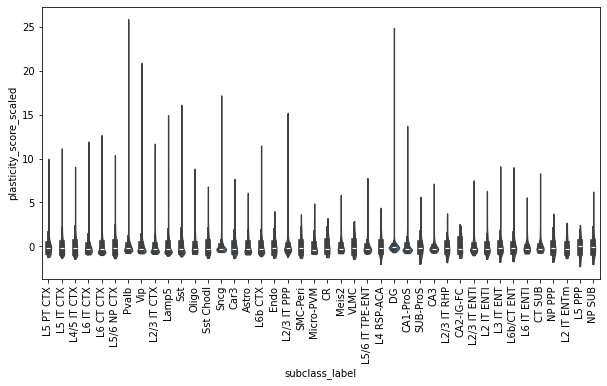

In [49]:
adata.obs["plasticity_score_scaled"] = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .transform(lambda x: (x - x.mean()) / (x.std() + 1e-8))
)

import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
sns.violinplot(data=adata.obs, x="subclass_label", y="plasticity_score_scaled", cut=0)

plt.xticks(rotation=90)
plt.show()

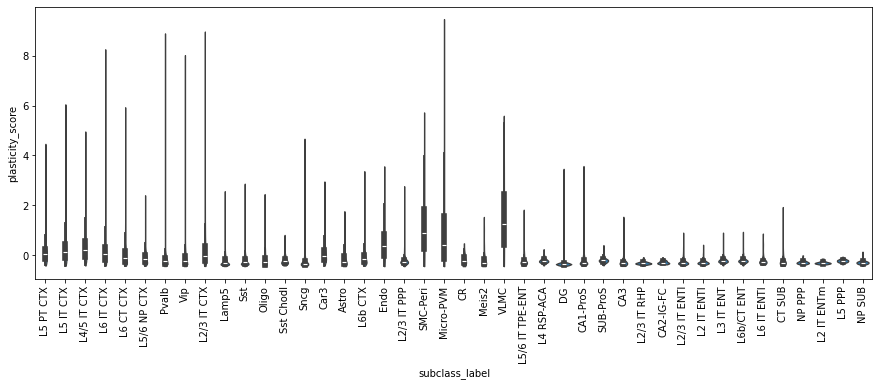

In [57]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 5))
sns.violinplot(data=adata.obs, x="subclass_label", y="plasticity_score", cut=0)

plt.xticks(rotation=90)
plt.show()

subclass_label
VLMC           1.519009
SMC-Peri       1.167332
Micro-PVM      1.013359
Endo           0.521817
L4/5 IT CTX    0.308083
L5 IT CTX      0.239475
L2/3 IT CTX    0.201080
L6 IT CTX      0.200970
L5 PT CTX      0.113722
Car3           0.076543
Name: plasticity_score, dtype: float64


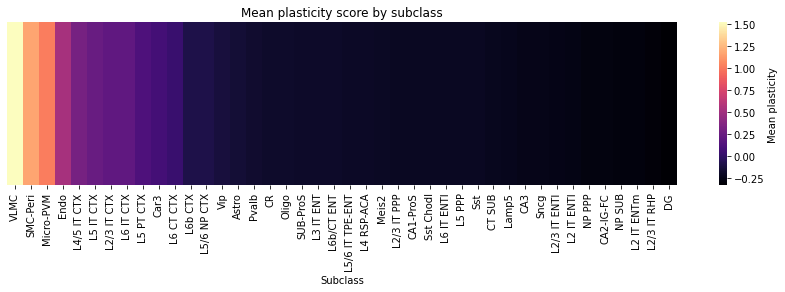

In [54]:
avg = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .mean()
    .sort_values(ascending=False)
)
print(avg.head(10))

plt.figure(figsize=(15, 3))
sns.heatmap(avg.to_frame().T, cmap="magma", cbar_kws={"label": "Mean plasticity"})
plt.yticks([])
plt.xlabel("Subclass")
plt.title("Mean plasticity score by subclass")
plt.show()


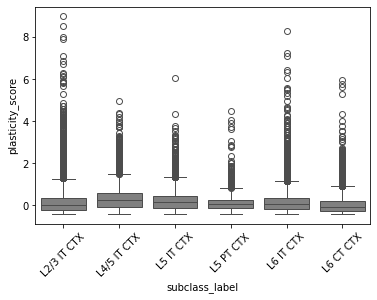

In [51]:
order = ["L2/3 IT CTX","L4/5 IT CTX","L5 IT CTX","L5 PT CTX","L6 IT CTX","L6 CT CTX"]
sns.boxplot(data=adata.obs, x="subclass_label", y="plasticity_score",
            order=order, color="gray")
plt.xticks(rotation=45)
plt.show()


                    mean       std  count
subclass_label                           
VLMC            1.519009  1.403977    120
SMC-Peri        1.167332  1.246476    133
Micro-PVM       1.013359  1.729198    178
Endo            0.521817  0.758455    197
L4/5 IT CTX     0.308083  0.514514  10854
L5 IT CTX       0.239475  0.521148   3750
L2/3 IT CTX     0.201080  0.750291   6003
L6 IT CTX       0.200970  0.676017   4658
L5 PT CTX       0.113722  0.436335   1750
Car3            0.076543  0.374684   1193


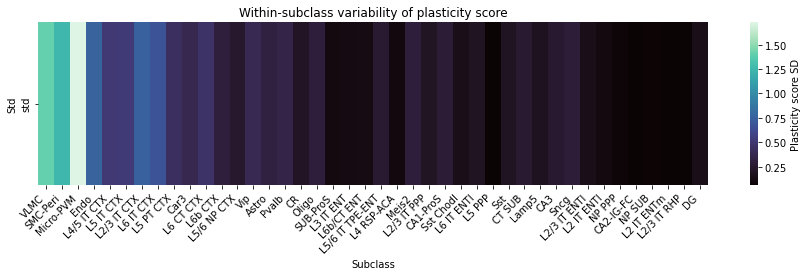

In [53]:
stats = (
    adata.obs
    .groupby("subclass_label")["plasticity_score"]
    .agg(["mean", "std", "count"])
    .sort_values("mean", ascending=False)
)
print(stats.head(10))
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 3))
sns.heatmap(
    stats[["std"]].T,          # one row (std) across subclasses
    cmap="mako",               # good for continuous low–high
    cbar_kws={"label": "Plasticity score SD"}
)
plt.title("Within-subclass variability of plasticity score")
plt.xlabel("Subclass")
plt.ylabel("Std")
plt.xticks(rotation=45, ha="right")
plt.show()


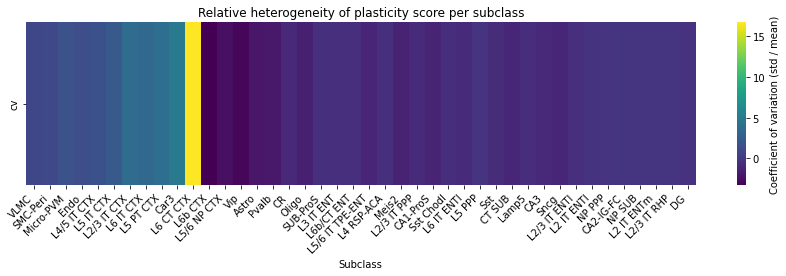

In [56]:
import numpy as np
stats["cv"] = stats["std"] / (stats["mean"].replace(0, np.nan))

plt.figure(figsize=(15,3))
sns.heatmap(
    stats[["cv"]].T,
    cmap="viridis",
    cbar_kws={"label": "Coefficient of variation (std / mean)"}
)
plt.title("Relative heterogeneity of plasticity score per subclass")
plt.xlabel("Subclass")
plt.xticks(rotation=45, ha="right")
plt.show()


In [58]:
adata_l5 = adata[adata.obs["subclass_label"].isin(["L5 IT CTX","L5 PT CTX"]), :].copy()


/tmp/ipykernel_22671/4254844710.py:24: UserWarning: Ignoring svd_solver='auto' and using arpack, sklearn.decomposition._pca.PCA (with sparse input) only supports dict_keys(['arpack']).
  sc.tl.pca(adata_l5_pl, n_comps=n_pc, svd_solver="auto")


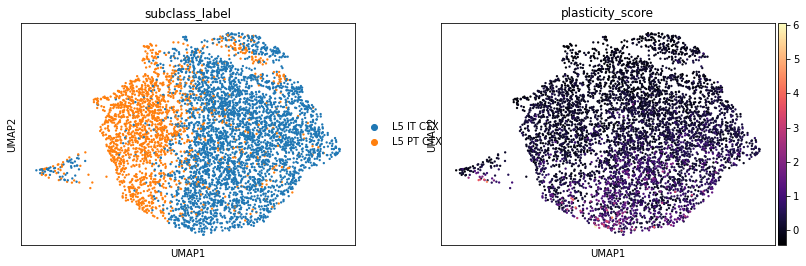

In [65]:
import scanpy as sc
import numpy as np

# --- L5 only (if you haven't already) ---
# adata_l5 = adata[adata.obs["subclass_label"].isin(["L5 IT CTX","L5 PT CTX"])].copy()

# pick plasticity genes present
genes_plastic = ["Fos","Fosb","Junb","Egr1","Egr2","Npas4","Arc","Nr4a1","Nr4a2",
                 "Bdnf","Nptx2","Syt4","Camk2g","Rgs4","Dusp1","Atf3","Crem",
                 "Gadd45b","Gadd45g","Prkcz"]
genes_plastic = [g for g in genes_plastic if g in adata_l5.var_names]

adata_l5_pl = adata_l5[:, genes_plastic].copy()

# basic preprocessing
sc.pp.normalize_total(adata_l5_pl, target_sum=1e4)
sc.pp.log1p(adata_l5_pl)

# avoid densifying if you want (optional); with 20 genes either is fine
sc.pp.scale(adata_l5_pl, zero_center=False)

# PCA: use fewer components than #genes
n_pc = max(2, min(10, len(genes_plastic)-1))
sc.tl.pca(adata_l5_pl, n_comps=n_pc, svd_solver="auto")

# neighbors/UMAP
sc.pp.neighbors(adata_l5_pl, n_neighbors=15, n_pcs=n_pc)
sc.tl.umap(adata_l5_pl)

# visualize
sc.pl.umap(adata_l5_pl, color=["subclass_label", "plasticity_score"], cmap="magma")


In [66]:
from scipy.stats import spearmanr

# Correlation between UMAP1/UMAP2 and plasticity_score
for axis in ["X_umap1", "X_umap2"]:
    corr, p = spearmanr(adata_l5_pl.obsm["X_umap"][:,0], adata_l5_pl.obs["plasticity_score"])
    print(f"Correlation {axis}: {corr:.3f}, p={p:.1e}")


Correlation X_umap1: 0.115, p=9.4e-18
Correlation X_umap2: 0.115, p=9.4e-18


/tmp/ipykernel_22671/3388029922.py:2: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_l5_pl, resolution=0.4)


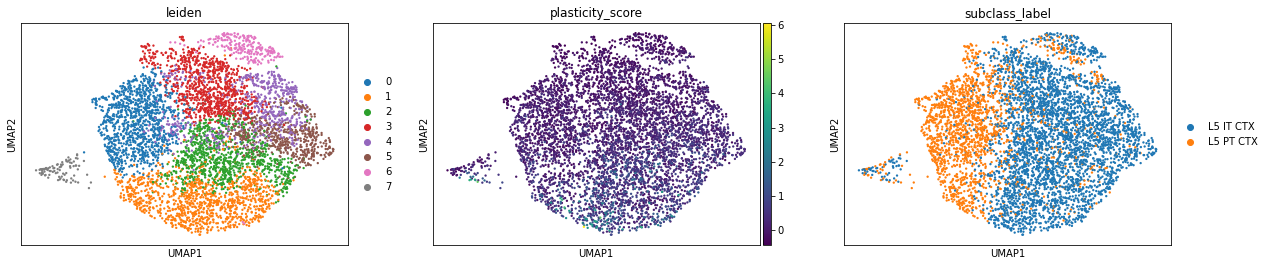

leiden
6   -0.092714
3   -0.044147
0    0.026182
4    0.046753
5    0.224000
2    0.373696
7    0.442525
1    0.551280
Name: plasticity_score, dtype: float64


In [61]:
# cluster
sc.tl.leiden(adata_l5_pl, resolution=0.4)
sc.pl.umap(adata_l5_pl, color=["leiden","plasticity_score","subclass_label"])

# do clusters track plasticity?
cluster_mean = adata_l5_pl.obs.groupby("leiden")["plasticity_score"].mean().sort_values()
print(cluster_mean)


/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:481: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:481: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (


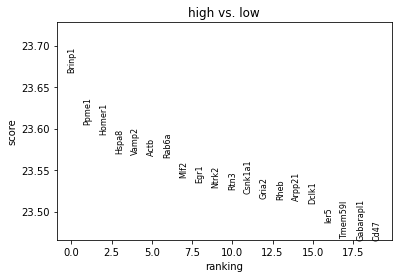

/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:481: RuntimeWarning: overflow encountered in expm1
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (
/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:482: RuntimeWarning: overflow encountered in expm1
  self.expm1_func(mean_rest) + 1e-9
/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:481: RuntimeWarning: invalid value encountered in divide
  foldchanges = (self.expm1_func(mean_group) + 1e-9) / (


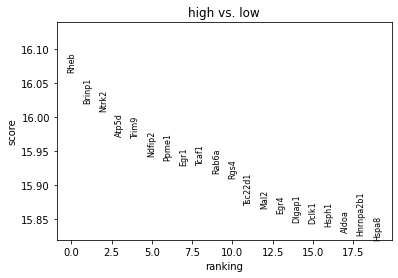

In [62]:
for grp in ["L5 IT CTX","L5 PT CTX"]:
    ad = adata_l5[adata_l5.obs["subclass_label"].eq(grp)].copy()
    qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
    ad.obs["plast_group"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                             np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))
    sc.tl.rank_genes_groups(ad, "plast_group", groups=["high"], reference="low", method="wilcoxon")
    sc.pl.rank_genes_groups(ad, n_genes=20, sharey=False, title=grp)


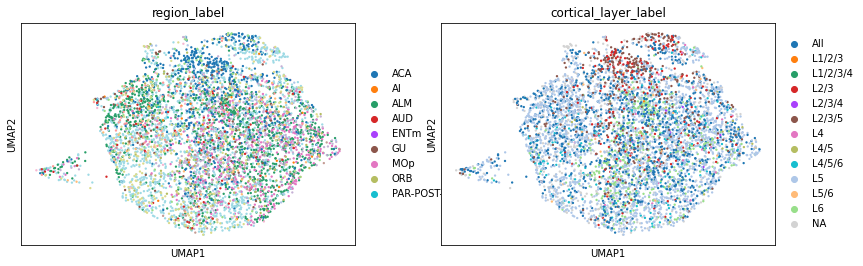

In [63]:
sc.pl.umap(adata_l5_pl, color=["region_label","cortical_layer_label"])



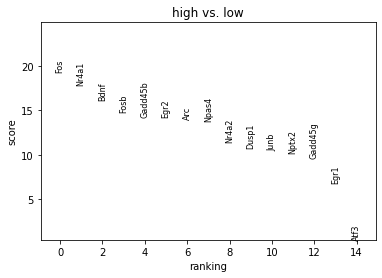

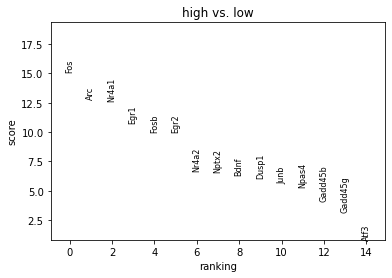

In [67]:
import numpy as np
for subclass in ["L5 IT CTX","L5 PT CTX"]:
    ad = adata_l5_pl[adata_l5_pl.obs["subclass_label"] == subclass].copy()
    qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
    ad.obs["state"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                       np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))
    sc.tl.rank_genes_groups(ad, "state", groups=["high"], reference="low", method="wilcoxon")
    sc.pl.rank_genes_groups(ad, n_genes=15, sharey=False, title=subclass)


/usr/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


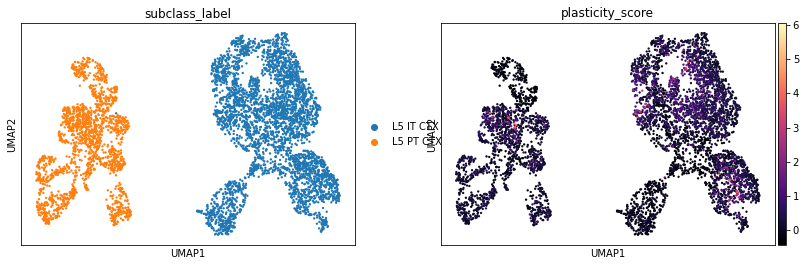

In [68]:
import scanpy as sc

adata_l5_all = adata_l5.copy()

sc.pp.normalize_total(adata_l5_all, target_sum=1e4)
sc.pp.log1p(adata_l5_all)
sc.pp.highly_variable_genes(adata_l5_all, n_top_genes=2000, flavor="seurat")
adata_l5_all = adata_l5_all[:, adata_l5_all.var["highly_variable"]].copy()
sc.pp.scale(adata_l5_all, max_value=10)
sc.tl.pca(adata_l5_all, n_comps=50)
sc.pp.neighbors(adata_l5_all, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_l5_all)

sc.pl.umap(adata_l5_all, color=["subclass_label", "plasticity_score"], cmap="magma")


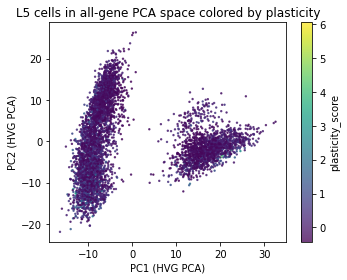

In [81]:
from scipy.sparse import issparse
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# After you've done HVG subsetting:
# adata_l5_all = adata_l5_all[:, adata_l5_all.var["highly_variable"]].copy()

# Dense arrays
def dense(X):
    return X.toarray() if issparse(X) else X

X_all = dense(adata_l5_all.X)  # shape: n_cells × 2000 (HVGs)

# Fit PCA on all-genes (HVG) space
pca_all = PCA(n_components=10, random_state=0).fit(X_all)

# Use the *same cells* and *same 2000 HVGs* for the "projection" matrix
# (these are the cells in your plasticity subset)
cells = adata_l5_pl.obs_names
X_pl_hvg = dense(adata_l5_all[cells, :].X)  # same 2000 features!

proj = pca_all.transform(X_pl_hvg)

plt.figure(figsize=(5,4))
scat = plt.scatter(proj[:,0], proj[:,1],
                   c=adata_l5_pl.obs["plasticity_score"].values, s=2, alpha=0.75)
plt.xlabel("PC1 (HVG PCA)"); plt.ylabel("PC2 (HVG PCA)")
plt.colorbar(scat, label="plasticity_score")
plt.title("L5 cells in all-gene PCA space colored by plasticity")
plt.tight_layout(); plt.show()


In [70]:
import statsmodels.api as sm
import pandas as pd

df = adata_l5_all.obs[["plasticity_score","subclass_label"]].copy()
df = pd.get_dummies(df, drop_first=True)  # encode subclass
X = sm.add_constant(df[["subclass_label_L5 PT CTX"]])
y = adata_l5_all.obs["plasticity_score"]
model = sm.OLS(y, X).fit()
print(model.summary())


                            OLS Regression Results                            
Dep. Variable:       plasticity_score   R-squared:                       0.014
Model:                            OLS   Adj. R-squared:                  0.014
Method:                 Least Squares   F-statistic:                     76.78
Date:                Sat, 01 Nov 2025   Prob (F-statistic):           2.51e-18
Time:                        22:11:12   Log-Likelihood:                -3943.8
No. Observations:                5500   AIC:                             7892.
Df Residuals:                    5498   BIC:                             7905.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                               coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------
const                   

/home/peter/.local/lib/python3.10/site-packages/scanpy/tools/_rank_genes_groups.py:484: RuntimeWarning: invalid value encountered in log2
  self.stats[group_name, "logfoldchanges"] = np.log2(


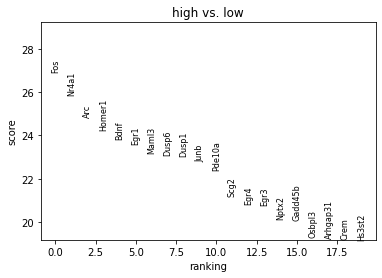

In [74]:
import scanpy as sc
import numpy as np

# work on the all-genes L5 object you already normalized/logged
ad = adata_l5_all.copy()

# define high/low states within L5
qh, ql = ad.obs["plasticity_score"].quantile([0.9, 0.1])
ad.obs["plast_group"] = np.where(ad.obs["plasticity_score"]>=qh,"high",
                         np.where(ad.obs["plasticity_score"]<=ql,"low","mid"))

# run DE (high vs low)
sc.tl.rank_genes_groups(ad, groupby="plast_group", groups=["high"], reference="low", method="wilcoxon")
sc.pl.rank_genes_groups(ad, n_genes=20, sharey=False)


In [77]:
from sklearn.decomposition import PCA

for s in ["L5 IT CTX","L5 PT CTX"]:
    sub = adata_l5_all[adata_l5_all.obs["subclass_label"]==s, genes_plastic].X.toarray()
    pc1 = PCA(n_components=1).fit_transform(sub)
    adata_l5_all.obs.loc[adata_l5_all.obs["subclass_label"]==s,"plasticity_PC1"] = pc1.ravel()


KeyError: "Values ['Fosb', 'Syt4', 'Camk2g', 'Prkcz'], from ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz'], are not valid obs/ var names or indices."

In [72]:
from scipy.stats import spearmanr
corrs = []
for g in adata_l5_all.var_names:
    r,_ = spearmanr(adata_l5_all[:,g].X.toarray().ravel(),
                    adata_l5_all.obs["plasticity_score"])
    corrs.append(r)


In [75]:
from scipy.stats import spearmanr
import pandas as pd

expr = adata_l5_all.X if not issparse(adata_l5_all.X) else adata_l5_all.X.toarray()
scores = adata_l5_all.obs["plasticity_score"].values
r = []
for i, g in enumerate(adata_l5_all.var_names):
    rho, p = spearmanr(expr[:, i], scores)
    r.append((g, rho, p))
corr_df = pd.DataFrame(r, columns=["gene","rho","p"]).sort_values("rho", ascending=False)
corr_df.head(20)  # top co-varying genes


,gene,rho,p
568,Fos,0.478692,0.000000e+00
946,Homer1,0.445420,2.311657e-266
133,Arc,0.435807,8.401412e-254
1262,Maml3,0.435252,4.331817e-253
189,Bdnf,0.422926,1.344376e-237
1389,Nr4a1,0.402088,7.729511e-213
1487,Pde10a,0.375051,2.970552e-183
455,Dusp1,0.372625,9.831679e-181
141,Arhgap31,0.372419,1.603421e-180
479,Egr3,0.368881,6.916067e-177


In [82]:
import statsmodels.api as sm
df = adata_l5_all.obs[["plasticity_score","subclass_label","region_label"]].copy()
df = pd.get_dummies(df, drop_first=True)
X = sm.add_constant(df.drop(columns="plasticity_score"))
y = df["plasticity_score"]
print(sm.OLS(y, X).fit().summary())


                            OLS Regression Results                            
Dep. Variable:       plasticity_score   R-squared:                       0.229
Model:                            OLS   Adj. R-squared:                  0.226
Method:                 Least Squares   F-statistic:                     90.37
Date:                Sat, 01 Nov 2025   Prob (F-statistic):          3.01e-292
Time:                        22:24:20   Log-Likelihood:                -3267.3
No. Observations:                5500   AIC:                             6573.
Df Residuals:                    5481   BIC:                             6698.
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
const                 

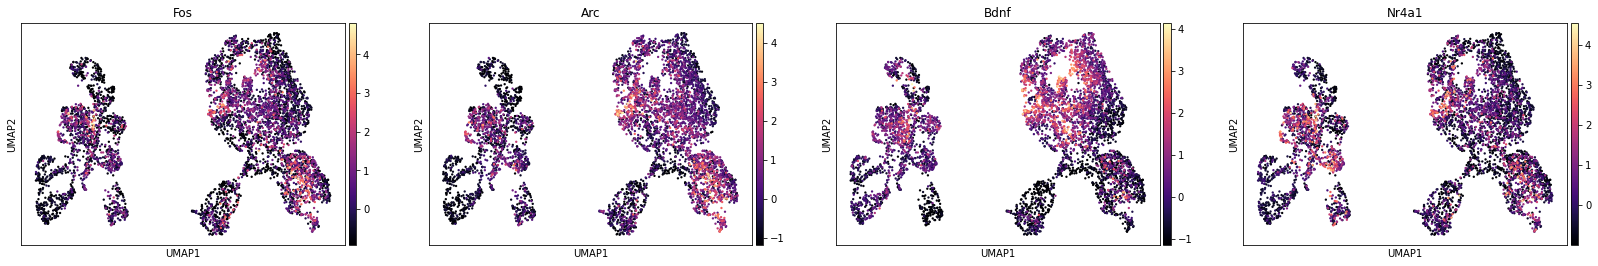

In [83]:
sc.pl.umap(adata_l5_all, color=["Fos","Arc","Bdnf","Nr4a1"], cmap="magma")

In [96]:
import pingouin as pg
import pandas as pd
from scipy.sparse import issparse

# Build a clean DataFrame
fos = adata_l5_all[:, "Fos"].X
fos = fos.toarray().ravel() if issparse(fos) else fos.ravel()

df = pd.DataFrame({
    "plasticity_score": adata_l5_all.obs["plasticity_score"].values,
    "Fos": fos,
    "region": adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})

# Option A: spearman (works now that covariates are numeric)
pg.partial_corr(data=df, x="Fos", y="plasticity_score",
                covar=["region","subclass"], method="spearman")




,n,r,CI95%,p-val
spearman,5500,0.448873,"[0.43, 0.47]",7.081307e-271


In [100]:
import numpy as np, pandas as pd
from scipy.sparse import issparse
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression

# --- Base DF with numeric covariates ---
base = pd.DataFrame({
    "plasticity_score": adata_l5_all.obs["plasticity_score"].values,
    "region": adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})
cov = base[["region","subclass"]].values

# Rank-transform for Spearman (monotone-invariant)
rank = base.copy()
rank["plasticity_score"] = rank["plasticity_score"].rank(method="average")

# Residualize plasticity wrt covariates
lr = LinearRegression()
lr.fit(cov, rank["plasticity_score"].values)
plast_resid = rank["plasticity_score"].values - lr.predict(cov)

def expr_dense(g):
    Xg = adata_l5_all[:, g].X
    return Xg.toarray().ravel() if issparse(Xg) else Xg.ravel()

genes_to_test = ["Fos","Arc","Bdnf","Nr4a1","Homer1","Dusp1","Nptx2","Egr1","Egr2","Egr3"]

rows = []
for g in genes_to_test:
    x = expr_dense(g)
    # rank, residualize, and drop NaNs per-gene
    valid = np.isfinite(x)
    x_rank = pd.Series(x[valid]).rank(method="average").values
    lr.fit(cov[valid], x_rank)
    x_resid = x_rank - lr.predict(cov[valid])
    r, p = spearmanr(x_resid, plast_resid[valid])
    rows.append({"gene": g, "r_partial": r, "p_partial": p, "n": int(valid.sum())})

pcorr_df = pd.DataFrame(rows).sort_values("r_partial", ascending=False)
pcorr_df


,gene,r_partial,p_partial,n
0,Fos,0.457292,1.917893e-282,5500
4,Homer1,0.454548,1.140897e-278,5500
2,Bdnf,0.423288,4.816296e-238,5500
3,Nr4a1,0.408889,1.000095e-220,5500
1,Arc,0.408237,5.818584e-220,5500
5,Dusp1,0.375976,3.204633e-184,5500
6,Nptx2,0.347999,2.370253e-156,5500
9,Egr3,0.335023,2.342473e-144,5500
7,Egr1,0.314694,1.068198e-126,5500
8,Egr2,0.264154,1.796312e-88,5500


<Axes: ylabel='region_label'>

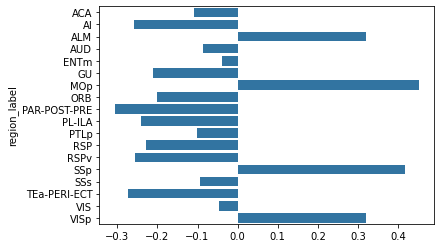

In [89]:
region_mean = adata_l5_all.obs.groupby("region_label")["plasticity_score"].mean().sort_values()
sns.barplot(y=region_mean.index, x=region_mean.values)


In [94]:
# assuming corr_df is your gene/rho/p table
top_genes = corr_df.head(100)["gene"].tolist()   # top 100 correlated genes

# top_genes already defined, e.g. corr_df.head(100)["gene"].tolist()
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)

gp_results = gp.profile(organism="mmusculus", query=top_genes)

# Inspect available columns
print(gp_results.columns.tolist())

# Nice compact view
out = (gp_results
       .sort_values("p_value")
       .loc[:, ["name","source","p_value","term_size","query_size","intersection_size"]]
       .head(15))
out



['source', 'native', 'name', 'p_value', 'significant', 'description', 'term_size', 'query_size', 'intersection_size', 'effective_domain_size', 'precision', 'recall', 'query', 'parents']


,name,source,p_value,term_size,query_size,intersection_size
0,system development,GO:BP,2.180154e-10,4155,91,45
1,regulation of signaling,GO:BP,3.648440e-09,3558,91,40
2,regulation of cell communication,GO:BP,3.715412e-09,3560,91,40
3,developmental process,GO:BP,4.203496e-09,6873,91,56
4,multicellular organism development,GO:BP,4.228887e-09,4907,91,47
5,signaling,GO:BP,7.417966e-09,7443,91,58
6,cell communication,GO:BP,9.007851e-09,7475,91,58
7,positive regulation of cellular process,GO:BP,1.026242e-08,6095,91,52
8,regulation of developmental process,GO:BP,1.508792e-08,2689,91,34
9,positive regulation of biological process,GO:BP,2.336110e-08,6447,91,53


In [99]:
top_genes

['Fos',
 'Homer1',
 'Arc',
 'Maml3',
 'Bdnf',
 'Nr4a1',
 'Pde10a',
 'Dusp1',
 'Arhgap31',
 'Egr3',
 'Nptx2',
 'Dusp6',
 'Egr1',
 'Scg2',
 'Egr2',
 'Hs3st2',
 'Junb',
 'Gadd45b',
 'Crem',
 'Kcnc2',
 'Sorcs3',
 'Adssl1',
 'Cdkn1a',
 'Sema3a',
 'Npas4',
 'Egr4',
 'Tnfaip6',
 'Gm34996',
 'Slc24a2',
 'Gm11549',
 'Prss23',
 'Kcnv1',
 'Tiparp',
 'Cyr61',
 'Serpinb8',
 'Osbpl3',
 'Etl4',
 'Pdp1',
 'Ubash3b',
 'Gpr133',
 'Ntng2',
 'Ptgs2',
 'Fstl4',
 'Fosl2',
 'Sgsm1',
 'Ptn',
 'Rxfp2',
 'Me3',
 'Diras2',
 'Mapk4',
 'Myl4',
 'Igfbp6',
 'Dlgap2',
 'Rgs4',
 'Pcsk1',
 'Igfbp7',
 'Arhgap15',
 'Ddah1',
 'H2-T23',
 'Ier3',
 'Erc2',
 'Enox1',
 'Gadd45g',
 'Nr4a3',
 'Anxa5',
 'Colq',
 'Traf5',
 'Ppp1r1a',
 'Nell1',
 'Pde7b',
 'Car10',
 'E530001K10Rik',
 'Nrsn1',
 'Dmkn',
 'Rnr1',
 'Bmpr1b',
 'Zc3h7a',
 'Lpar1',
 'Cpne9',
 'Rgs2',
 'Olfr111',
 'Lingo1',
 'Robo2',
 'Dok5',
 'Plcl1',
 'Tmeff1',
 'Rims1',
 'Metrnl',
 'Trhde',
 'Glis3',
 'Herc6',
 'Il17ra',
 'Inhba',
 'Vgf',
 'Ntrk2',
 'Hgf',
 'Zbtb16',
 'F

In [101]:
import numpy as np, pandas as pd
from scipy.sparse import issparse
from scipy.stats import spearmanr
from sklearn.linear_model import LinearRegression
from statsmodels.stats.multitest import multipletests

# numeric covariates
cov = pd.DataFrame({
    "region":   adata_l5_all.obs["region_label"].astype("category").cat.codes,
    "subclass": adata_l5_all.obs["subclass_label"].astype("category").cat.codes,
})
y = adata_l5_all.obs["plasticity_score"].values

# rank + residualize plasticity
y_rank = pd.Series(y).rank(method="average").values
lr = LinearRegression().fit(cov.values, y_rank)
y_resid = y_rank - lr.predict(cov.values)

def expr_vec(g):
    Xg = adata_l5_all[:, g].X
    return (Xg.toarray().ravel() if issparse(Xg) else np.asarray(Xg).ravel())

rows = []
for g in adata_l5_all.var_names:
    x = expr_vec(g)
    valid = np.isfinite(x)
    if valid.sum() < 3 or np.all(x[valid]==x[valid][0]):  # constant/too few
        continue
    x_rank = pd.Series(x[valid]).rank(method="average").values
    lr.fit(cov.values[valid], x_rank)
    x_resid = x_rank - lr.predict(cov.values[valid])
    r, p = spearmanr(x_resid, y_resid[valid])
    rows.append((g, r, p, int(valid.sum())))

pcorr = pd.DataFrame(rows, columns=["gene","r_partial","p_partial","n"])
pcorr["q_partial"] = multipletests(pcorr["p_partial"], method="fdr_bh")[1]
pcorr = pcorr.sort_values("q_partial")
pcorr.to_csv("plasticity_partial_corr_L5_allgenes.csv", index=False)
pcorr.head(20)


,gene,r_partial,p_partial,n,q_partial
568,Fos,0.457292,1.917893e-282,5500,3.835786e-279
946,Homer1,0.454548,1.140897e-278,5500,1.140897e-275
1262,Maml3,0.425350,1.358753e-240,5500,9.058356e-238
189,Bdnf,0.423288,4.816296e-238,5500,2.408148e-235
1389,Nr4a1,0.408889,1.000095e-220,5500,4.000381e-218
133,Arc,0.408237,5.818584e-220,5500,1.939528e-217
455,Dusp1,0.375976,3.204633e-184,5500,9.156094e-182
1487,Pde10a,0.367214,3.437841e-175,5500,8.594603e-173
596,Gadd45b,0.365907,7.232059e-174,5500,1.607124e-171
1386,Nptx2,0.347999,2.370253e-156,5500,4.740507e-154


module vs original: 0.6008673436560205 0.0


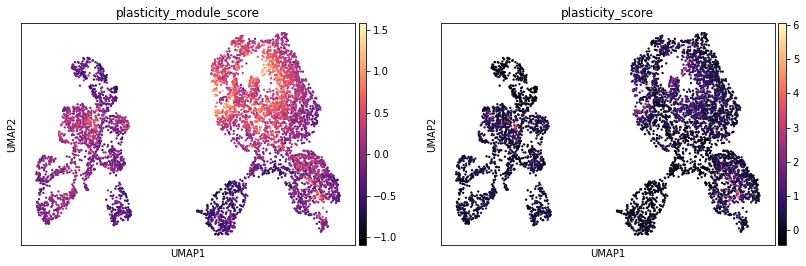

In [102]:
# choose top 100 by partial correlation
top_plastic = pcorr.sort_values("r_partial", ascending=False).head(100)["gene"].tolist()

# score per cell (Scanpy’s built-in module score)
import scanpy as sc
sc.tl.score_genes(adata_l5_all, gene_list=top_plastic, score_name="plasticity_module_score")

# sanity: correlate with your original plasticity_score
from scipy.stats import spearmanr
rho, p = spearmanr(adata_l5_all.obs["plasticity_score"], adata_l5_all.obs["plasticity_module_score"])
print("module vs original:", rho, p)

# visualize
sc.pl.umap(adata_l5_all, color=["plasticity_module_score","plasticity_score"], cmap="magma")


In [103]:
from gprofiler import GProfiler
gp = GProfiler(return_dataframe=True)
top_genes = pcorr.sort_values("r_partial", ascending=False).head(150)["gene"].tolist()

gp_results = gp.profile(
    organism="mmusculus",
    query=top_genes,
    sources=["GO:BP","REAC","KEGG"],
    user_threshold=0.05,
    all_results=True,
    ordered=True
).sort_values("p_value")

cols = ["name","source","p_value","term_size","query_size","intersection_size"]
print(gp_results[cols].head(20))
gp_results.to_csv("enrichment_plasticity_top150.csv", index=False)

# optional: filter for nervous-system/synaptic keywords
focus = gp_results[gp_results["name"].str.contains(
    "synap|plastic|memory|LTP|MAPK|ERK|cAMP|CREB|neurotroph|glutamat|GABA",
    case=False)]
focus[cols].head(20)


                                            name source       p_value  \
0                             system development  GO:BP  2.510426e-18   
1             multicellular organism development  GO:BP  7.845028e-16   
2                          developmental process  GO:BP  2.556092e-15   
3                             cell communication  GO:BP  6.702540e-14   
4                        regulation of signaling  GO:BP  1.609892e-13   
5               regulation of cell communication  GO:BP  1.652500e-13   
6                                      signaling  GO:BP  2.160521e-13   
7               anatomical structure development  GO:BP  2.543623e-13   
8                     nervous system development  GO:BP  4.108318e-13   
9                           cell differentiation  GO:BP  2.150261e-12   
10                cellular developmental process  GO:BP  2.172025e-12   
11                      animal organ development  GO:BP  2.738737e-12   
13          anterograde trans-synaptic signaling  G

,name,source,p_value,term_size,query_size,intersection_size
13,anterograde trans-synaptic signaling,GO:BP,3.264914e-12,904,79,23
12,chemical synaptic transmission,GO:BP,3.264914e-12,904,79,23
14,trans-synaptic signaling,GO:BP,3.940348e-12,912,79,23
16,synaptic signaling,GO:BP,1.004512e-11,953,79,23
19,modulation of chemical synaptic transmission,GO:BP,5.993132e-11,719,79,20
20,regulation of trans-synaptic signaling,GO:BP,6.150683e-11,720,79,20
23,memory,GO:BP,1.262482e-10,168,75,12
30,learning or memory,GO:BP,1.113170e-09,329,75,14
46,synapse organization,GO:BP,5.381616e-08,630,140,21
55,regulation of synaptic plasticity,GO:BP,1.305557e-07,382,75,13


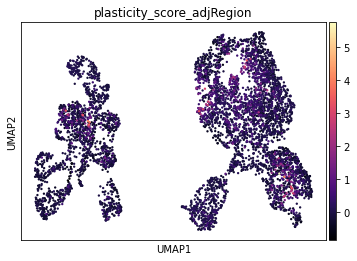

In [104]:
# regress out region from plasticity_score to show within-region variability
from sklearn.linear_model import LinearRegression
reg_codes = adata_l5_all.obs["region_label"].astype("category").cat.codes.values
X = pd.get_dummies(reg_codes).values  # one-hot region
adj = LinearRegression().fit(X, y).resid if hasattr(LinearRegression(), "resid") else y - LinearRegression().fit(X, y).predict(X)
adata_l5_all.obs["plasticity_score_adjRegion"] = adj

sc.pl.umap(adata_l5_all, color="plasticity_score_adjRegion", cmap="magma")


<Axes: xlabel='mean', ylabel='region_label'>

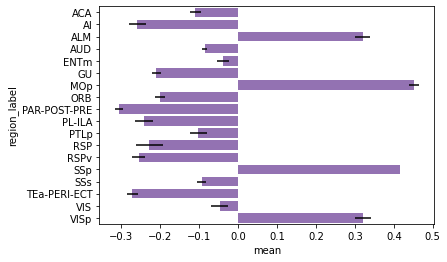

In [105]:
import seaborn as sns, numpy as np
g = (adata_l5_all.obs.groupby("region_label")["plasticity_score"]
     .agg(["mean","count","std"]).sort_values("mean"))
g["sem"] = g["std"]/np.sqrt(g["count"])
sns.barplot(y=g.index, x=g["mean"], xerr=g["sem"], color="tab:purple")


In [106]:
import scanpy as sc
sc.tl.dendrogram(adata_l5_all, groupby="region_label", use_rep="X_pca")


FileNotFoundError: [Errno 2] No such file or directory: 'cell_feature_definitions.csv'